In [ ]:
path='/content/healthcare-dataset-stroke-data.csv'

import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

import seaborn as sns

plt.figure(figsize=(12,4))

plt.style.use('ggplot')

from sklearn.linear_model import LogisticRegression

from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier

from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import train_test_split as tts

from sklearn.preprocessing import PowerTransformer

from sklearn.metrics import (accuracy_score,
precision_score,
recall_score,
f1_score,
matthews_corrcoef,
confusion_matrix,
classification_report)

#DL

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import Dense,Dropout

from tensorflow.keras.callbacks import EarlyStopping


<Figure size 1200x400 with 0 Axes>

# 📘 Data Dictionary – Stroke Prediction Dataset

| Feature | Data Type | Description | Possible Values / Range | Missing Values |
|----------|-----------|-------------|--------------------------|----------------|
| **id** | Integer | Unique identifier assigned to each patient. This column is only used for identification and should not be used for model training. | Unique Integer | No |
| **gender** | Categorical | Biological gender of the patient. | Male, Female, Other | No |
| **age** | Float | Age of the patient in years. | 0.08 – 82.0 years | No |
| **hypertension** | Binary (0/1) | Indicates whether the patient has hypertension (high blood pressure). | 0 = No, 1 = Yes | No |
| **heart_disease** | Binary (0/1) | Indicates whether the patient has any heart disease. | 0 = No, 1 = Yes | No |
| **ever_married** | Categorical | Indicates whether the patient has ever been married. | Yes, No | No |
| **work_type** | Categorical | Type of employment of the patient. | Private, Self-employed, Govt_job, Children, Never_worked | No |
| **Residence_type** | Categorical | Type of residence where the patient lives. | Urban, Rural | No |
| **avg_glucose_level** | Float | Average blood glucose level of the patient measured in mg/dL. | Continuous Numeric | No |
| **bmi** | Float | Body Mass Index (BMI) of the patient. BMI is calculated as weight (kg) divided by height² (m²). | Continuous Numeric | **Yes (201 Missing Values)** |
| **smoking_status** | Categorical | Smoking history of the patient. | Never Smoked, Formerly Smoked, Smokes, Unknown | No |
| **stroke** | Binary (Target Variable) | Indicates whether the patient has experienced a stroke. | 0 = No Stroke, 1 = Stroke | No |

---

## 🎯 Target Variable

**stroke**

- **0** → Patient did **not** experience a stroke.
- **1** → Patient **experienced** a stroke.

---

## 📊 Dataset Summary

- **Total Records:** 5,110
- **Total Features:** 12
- **Target Variable:** `stroke`
- **Numerical Features:** `age`, `avg_glucose_level`, `bmi`
- **Binary Features:** `hypertension`, `heart_disease`, `stroke`
- **Categorical Features:** `gender`, `ever_married`, `work_type`, `Residence_type`, `smoking_status`
- **Identifier Column:** `id`
- **Missing Values:** Present only in the **BMI** column (201 records)

> **Note:** The `id` column is a unique identifier and should generally be removed before training machine learning models since it carries no predictive information.

In [ ]:
df = pd.read_csv(path)

df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [ ]:
df.shape

(5110, 12)

In [ ]:
df.columns

Index(['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [ ]:
print("=" * 60)
print("📌 First 5 Rows of the Dataset")
print("=" * 60)
print(df.head())

print("\n" + "=" * 60)
print("📌 Last 5 Rows of the Dataset")
print("=" * 60)
print(df.tail())

print("\n" + "=" * 60)
print("📌 Random Sample from the Dataset")
print("=" * 60)
print(df.sample())

print("\n" + "=" * 60)
print("📌 Dataset Shape (Rows, Columns)")
print("=" * 60)
print(df.shape)

print("\n" + "=" * 60)
print("📌 Dataset Information")
print("=" * 60)
df.info()

print("\n" + "=" * 60)
print("📌 Statistical Summary of Numerical Columns")
print("=" * 60)
print(df.describe())


📌 First 5 Rows of the Dataset
      id  gender   age  hypertension  heart_disease ever_married  \
0   9046    Male  67.0             0              1          Yes   
1  51676  Female  61.0             0              0          Yes   
2  31112    Male  80.0             0              1          Yes   
3  60182  Female  49.0             0              0          Yes   
4   1665  Female  79.0             1              0          Yes   

       work_type Residence_type  avg_glucose_level   bmi   smoking_status  \
0        Private          Urban             228.69  36.6  formerly smoked   
1  Self-employed          Rural             202.21   NaN     never smoked   
2        Private          Rural             105.92  32.5     never smoked   
3        Private          Urban             171.23  34.4           smokes   
4  Self-employed          Rural             174.12  24.0     never smoked   

   stroke  
0       1  
1       1  
2       1  
3       1  
4       1  

📌 Last 5 Rows of the Data

In [ ]:
100*df.isna().sum()/len(df)

,0
id,0.000000
gender,0.000000
age,0.000000
hypertension,0.000000
heart_disease,0.000000
ever_married,0.000000
work_type,0.000000
Residence_type,0.000000
avg_glucose_level,0.000000
bmi,3.933464


#Missing value heatmap

<Axes: >

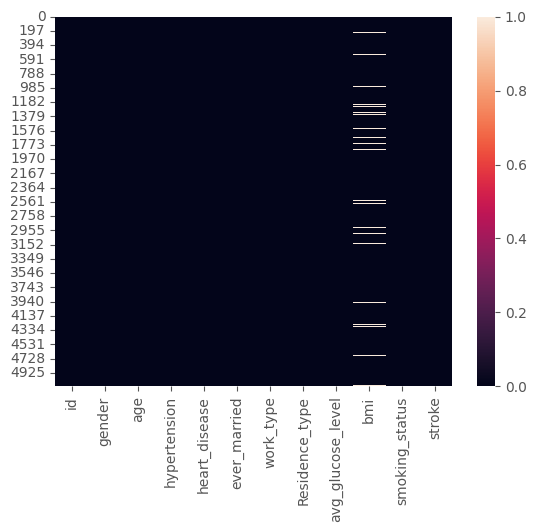

In [ ]:
sns.heatmap(df.isna())

#FIX missing values in BMI column

In [ ]:
df['bmi'].mean()

np.float64(28.893236911794666)

In [ ]:
df['bmi'].median()

28.1

In [ ]:
df['bmi'].fillna(df['bmi'].median(),inplace=True)

In [ ]:
df.isna().sum()

,0
id,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,0


#Duplicate Analysis

In [ ]:
df.duplicated().sum()

np.int64(0)

Verify:

- Numerical columns

- Categorical columns

- Target column


In [ ]:
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,28.1,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [ ]:
df.drop(['id'],axis=1,inplace=True)

In [ ]:
df.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,28.1,never smoked,1
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [ ]:
num_cols = []
cat_cols = []
for col in df.columns:
  if len(df[col].unique())>5:
    num_cols.append(col)
  elif len(df[col].unique())<=5:
    cat_cols.append(col)

num_cols

['age', 'avg_glucose_level', 'bmi']

In [ ]:
cat_cols.remove('stroke')

In [ ]:
cat_cols

['gender',
 'hypertension',
 'heart_disease',
 'ever_married',
 'work_type',
 'Residence_type',
 'smoking_status']

#Exploratory Data Analysis (EDA)

#How many stroke cases exist?

In [ ]:
df['stroke'].value_counts(normalize=True)*100

,proportion
stroke,
0,95.127202
1,4.872798


- 249 stroke cases exist equalling to 4.87 %

#Class imbalance severity?

- 0	95.127202%

- 1	4.872798%

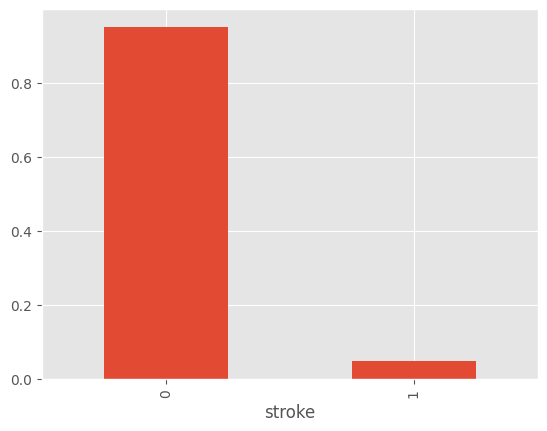

In [ ]:
df['stroke'].value_counts(normalize=True).plot.bar()
plt.show()

#Univariate Analysis

In [ ]:
df.describe()

,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000
mean,43.226614,0.097456,0.054012,106.147677,28.862035,0.048728
std,22.612647,0.296607,0.226063,45.283560,7.699562,0.215320
min,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,25.000000,0.000000,0.000000,77.245000,23.800000,0.000000
50%,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,61.000000,0.000000,0.000000,114.090000,32.800000,0.000000
max,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [ ]:
num_cols

['age', 'avg_glucose_level', 'bmi']

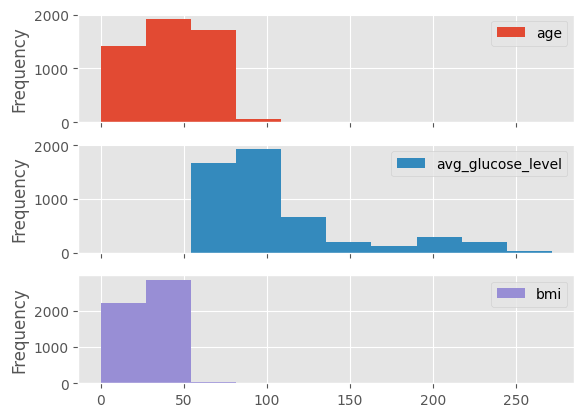

In [ ]:
df[num_cols].plot(kind='hist',subplots=True)
plt.show()

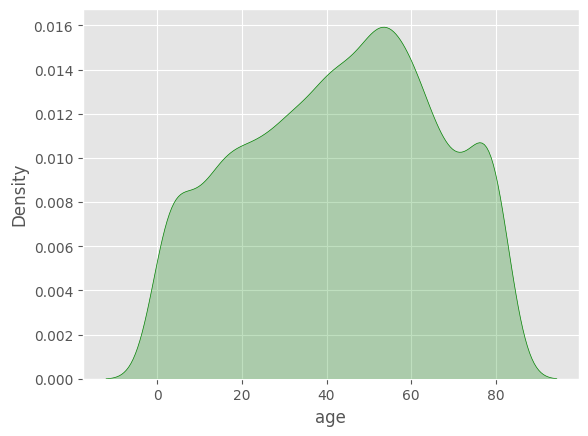

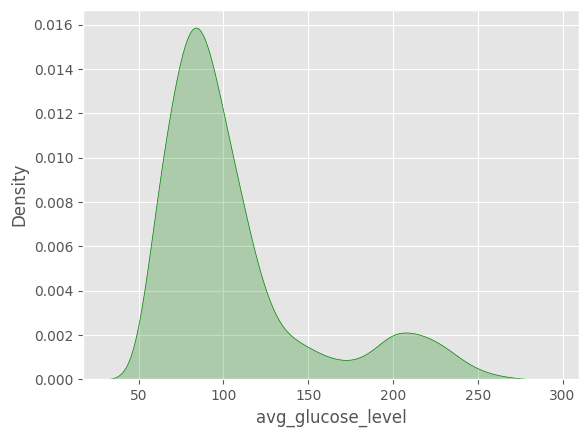

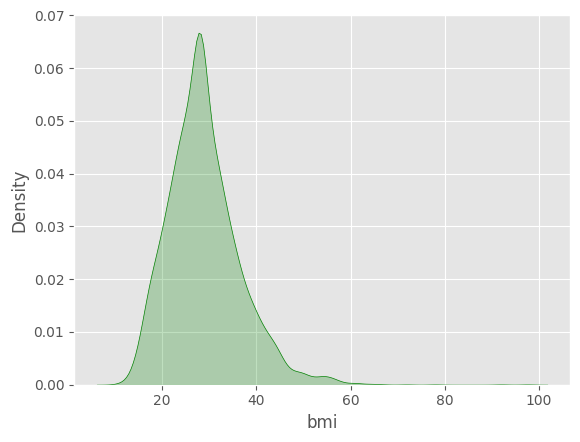

In [ ]:
for col in num_cols:
  sns.kdeplot(df[col],fill=True,color='g')
  plt.show()

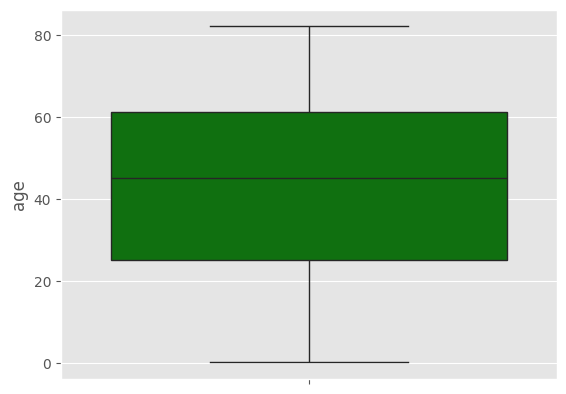

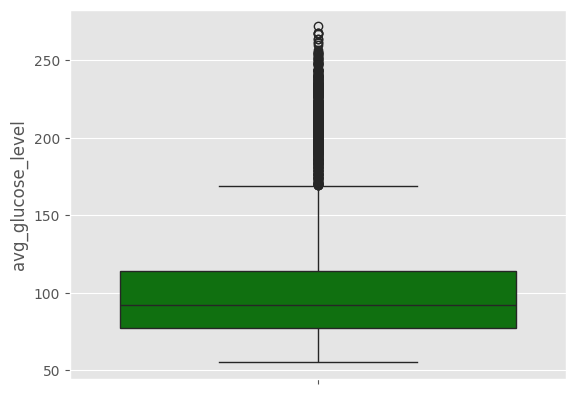

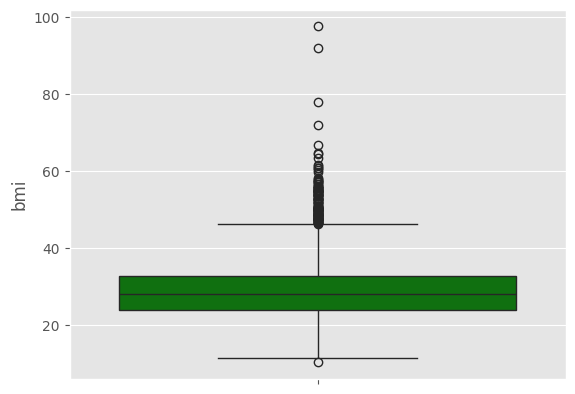

In [ ]:
for col in num_cols:
  sns.boxplot(df[col],color='g')
  plt.show()

#Categorical Variable Analysis

In [ ]:
cat_cols

['gender',
 'hypertension',
 'heart_disease',
 'ever_married',
 'work_type',
 'Residence_type',
 'smoking_status']

In [ ]:
for col in cat_cols:
  print('-'*100)
  print(df.groupby([col])['stroke'].mean())
  print('-'*100)

----------------------------------------------------------------------------------------------------
gender
Female    0.047094
Male      0.051064
Other     0.000000
Name: stroke, dtype: float64
----------------------------------------------------------------------------------------------------
----------------------------------------------------------------------------------------------------
hypertension
0    0.039679
1    0.132530
Name: stroke, dtype: float64
----------------------------------------------------------------------------------------------------
----------------------------------------------------------------------------------------------------
heart_disease
0    0.041787
1    0.170290
Name: stroke, dtype: float64
----------------------------------------------------------------------------------------------------
----------------------------------------------------------------------------------------------------
ever_married
No     0.016505
Yes    0.065613
Name: stroke, 

In [ ]:
df[df['gender']=='Other']

#?? drop this row

df.drop([3116],axis=0,inplace=True)

age vs stroke

bmi vs stroke

avg_glucose_level vs stroke

hypertension vs stroke

smoking_status vs stroke

heart_disease vs stroke


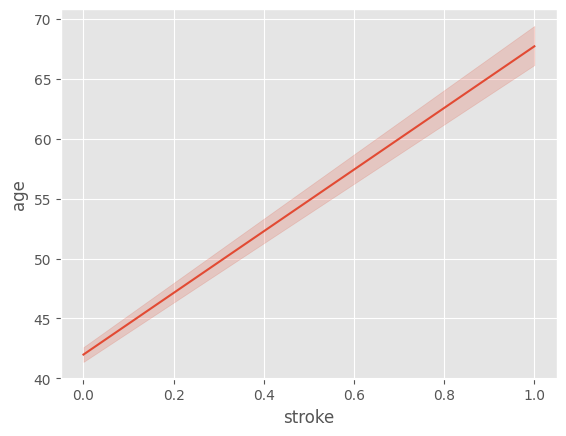

In [ ]:
sns.lineplot(x = 'stroke',y='age',data=df)
plt.show()

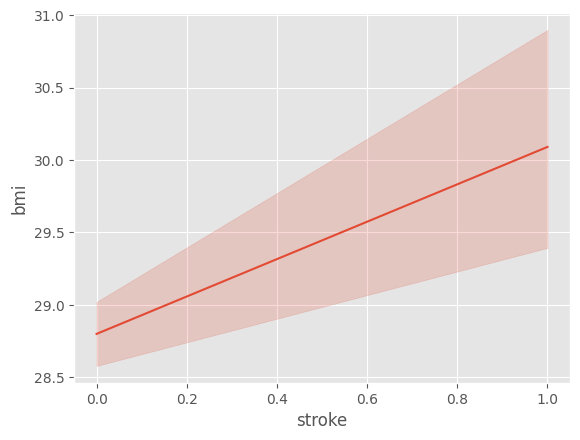

In [ ]:
sns.lineplot(x = 'stroke',y='bmi',data=df)
plt.show()

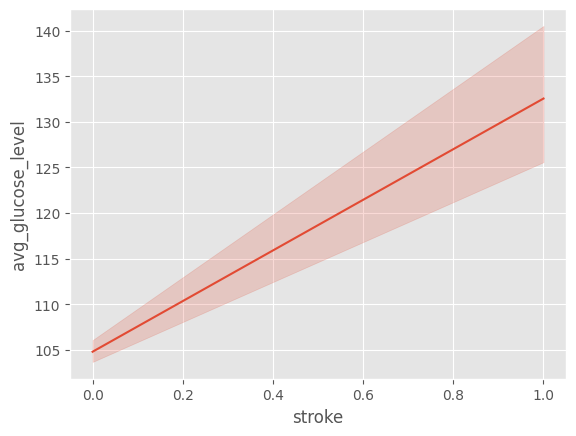

In [ ]:
sns.lineplot(x = 'stroke',y='avg_glucose_level',data=df)
plt.show()

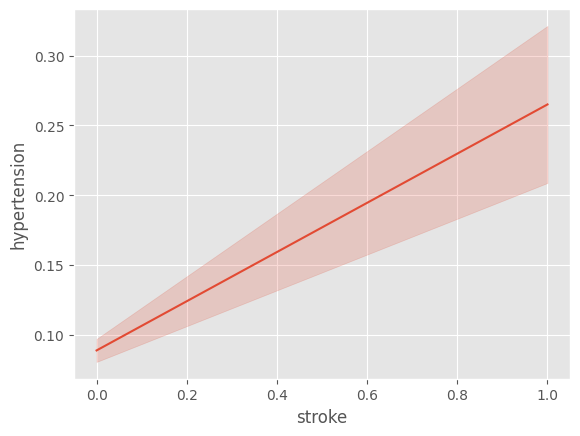

In [ ]:
sns.lineplot(x = 'stroke',y='hypertension',data=df)
plt.show()

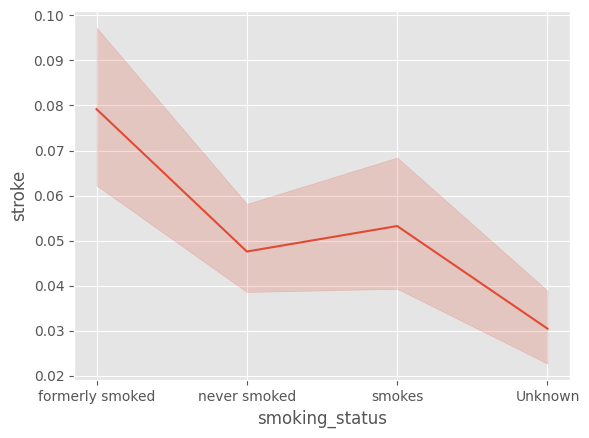

In [ ]:
sns.lineplot(x = 'smoking_status',y='stroke',data=df)
plt.show()

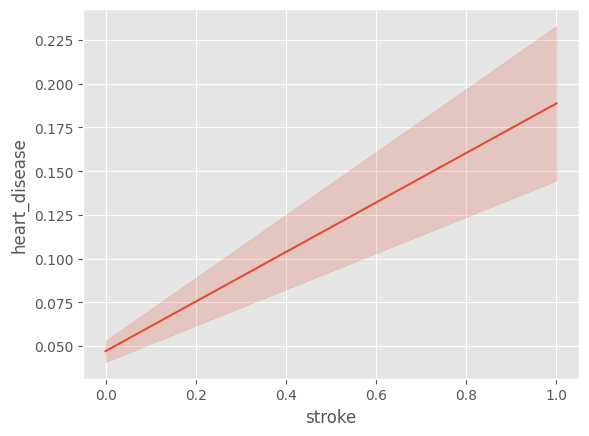

In [ ]:
sns.lineplot(x = 'stroke',y='heart_disease',data=df)
plt.show()

#Correlation Analysis

In [ ]:
df.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,28.1,never smoked,1
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


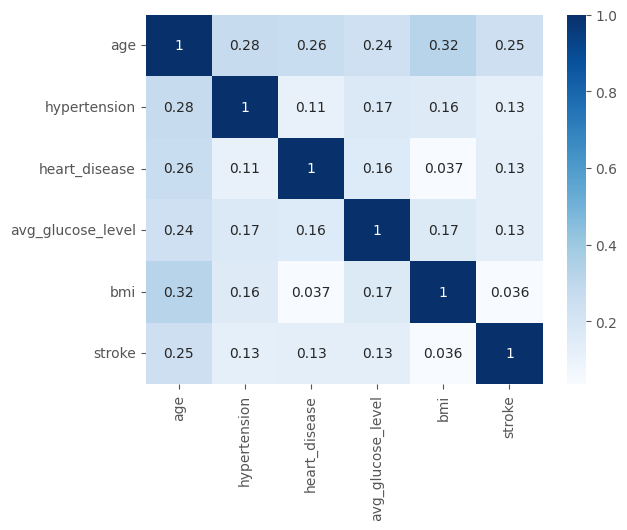

In [ ]:
sns.heatmap(df.corr(numeric_only=True),annot=True,cmap='Blues')
plt.show()

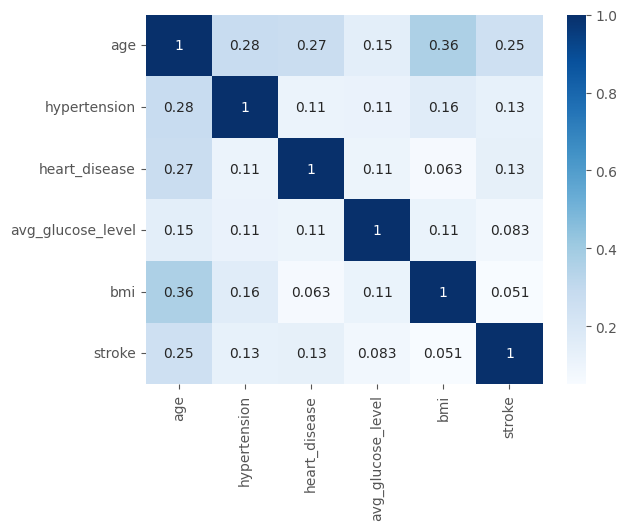

In [ ]:
sns.heatmap(df.corr(numeric_only=True,method='spearman'),annot=True,cmap='Blues')
plt.show()

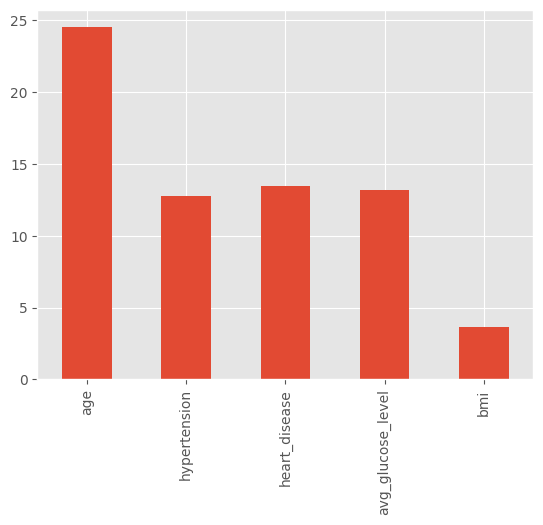

In [ ]:
(df.corr(numeric_only=True)['stroke'].drop(['stroke'])*100).plot.bar()
plt.show()

In [ ]:
df[num_cols].skew()

,0
age,-0.137430
avg_glucose_level,1.572815
bmi,1.087929


In [ ]:
df[num_cols].kurtosis()

,0
age,-0.990931
avg_glucose_level,1.681721
bmi,3.635026


In [ ]:
pt = PowerTransformer(method='yeo-johnson')

df[num_cols] = pt.fit_transform(df[num_cols])

df[num_cols].skew()

,0
age,-0.278969
avg_glucose_level,0.084579
bmi,-0.001035


In [ ]:
df[num_cols].kurtosis()

,0
age,-0.889662
avg_glucose_level,-0.499375
bmi,0.359740


#Feature Engineering

In [ ]:
df.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,1.032769,0,1,Yes,Private,Urban,1.862392,1.045197,formerly smoked,1
1,Female,0.788093,0,0,Yes,Self-employed,Rural,1.700511,0.026753,never smoked,1
2,Male,1.552975,0,1,Yes,Private,Rural,0.395031,0.587449,never smoked,1
3,Female,0.288329,0,0,Yes,Private,Urban,1.445120,0.806387,smokes,1
4,Female,1.513397,1,0,Yes,Self-employed,Rural,1.472918,-0.580998,never smoked,1


In [ ]:
df.isna().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,0
smoking_status,0


In [ ]:
df['work_type'].unique()

array(['Private', 'Self-employed', 'Govt_job', 'children', 'Never_worked'],
      dtype=object)

In [ ]:
# Encode Gender
df["gender"] = df["gender"].map({
    "Male": 0,
    "Female": 1
})

# Encode Ever Married
df["ever_married"] = df["ever_married"].map({
    "No": 0,
    "Yes": 1
})

# Encode Work Type
df["work_type"] = df["work_type"].map({
    "Private": 0,
    "Self-employed": 1,
    "Govt_job": 2,
    "children": 3,
    "Never_worked": 4
})

# Encode Residence Type
df["Residence_type"] = df["Residence_type"].map({
    "Rural": 0,
    "Urban": 1
})

# Encode Smoking Status
df["smoking_status"] = df["smoking_status"].map({
    "never smoked": 0,
    "formerly smoked": 1,
    "smokes": 2,
    "Unknown": 3
})

In [ ]:
df.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,0,1.032769,0,1,1,0,1,1.862392,1.045197,1,1
1,1,0.788093,0,0,1,1,0,1.700511,0.026753,0,1
2,0,1.552975,0,1,1,0,0,0.395031,0.587449,0,1
3,1,0.288329,0,0,1,0,1,1.445120,0.806387,2,1
4,1,1.513397,1,0,1,1,0,1.472918,-0.580998,0,1


now give me top 5 features that can be engineered from the existing features that will help uncover critical insights and also help boost ml and dl model performance for stroke classification

In [ ]:
df["cardio_risk_score"] = (
    df["hypertension"] +
    df["heart_disease"] +
    (df["avg_glucose_level"] >= 126).astype(int) +
    (df["smoking_status"] == 2).astype(int)
)

df["age_hypertension"] = df["age"] * df["hypertension"]


df["age_heart_disease"] = df["age"] * df["heart_disease"]

df["overall_health_risk"] = (
    df["cardio_risk_score"] +
    (df["bmi"] >= 30).astype(int) +
    (df["age"] >= 60).astype(int)
)

# Elderly smoker
df["elderly_smoker"] = (
    ((df["age"] >= 60) & (df["smoking_status"] == 2))
).astype(int)

# Married senior
df["married_senior"] = (
    ((df["ever_married"] == 1) & (df["age"] >= 60))
).astype(int)

# Glucose per BMI
df["glucose_bmi_ratio"] = df["avg_glucose_level"] / (df["bmi"] + 1)

# Cardiovascular burden
df["disease_burden"] = (
    df["hypertension"] +
    df["heart_disease"]
)

# Age × Glucose
df["age_glucose"] = df["age"] * df["avg_glucose_level"]

In [ ]:
df.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke,cardio_risk_score,age_hypertension,age_heart_disease,overall_health_risk,elderly_smoker,married_senior,glucose_bmi_ratio,disease_burden,age_glucose
0,0,1.032769,0,1,1,0,1,1.862392,1.045197,1,1,1,0.000000,1.032769,1,0,0,0.910617,1,1.923420
1,1,0.788093,0,0,1,1,0,1.700511,0.026753,0,1,0,0.000000,0.000000,0,0,0,1.656203,0,1.340161
2,0,1.552975,0,1,1,0,0,0.395031,0.587449,0,1,1,0.000000,1.552975,1,0,0,0.248846,1,0.613473
3,1,0.288329,0,0,1,0,1,1.445120,0.806387,2,1,1,0.000000,0.000000,1,0,0,0.800005,0,0.416670
4,1,1.513397,1,0,1,1,0,1.472918,-0.580998,0,1,1,1.513397,0.000000,1,0,0,3.515299,1,2.229110


In [ ]:
df.columns

Index(['gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke', 'cardio_risk_score', 'age_hypertension',
       'age_heart_disease', 'overall_health_risk', 'elderly_smoker',
       'married_senior', 'glucose_bmi_ratio', 'disease_burden', 'age_glucose'],
      dtype='object')

In [ ]:
df = df[['gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'cardio_risk_score', 'age_hypertension',
       'age_heart_disease', 'overall_health_risk', 'elderly_smoker',
       'married_senior', 'glucose_bmi_ratio', 'disease_burden', 'age_glucose', 'stroke']]

df.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,cardio_risk_score,age_hypertension,age_heart_disease,overall_health_risk,elderly_smoker,married_senior,glucose_bmi_ratio,disease_burden,age_glucose,stroke
0,0,1.032769,0,1,1,0,1,1.862392,1.045197,1,1,0.000000,1.032769,1,0,0,0.910617,1,1.923420,1
1,1,0.788093,0,0,1,1,0,1.700511,0.026753,0,0,0.000000,0.000000,0,0,0,1.656203,0,1.340161,1
2,0,1.552975,0,1,1,0,0,0.395031,0.587449,0,1,0.000000,1.552975,1,0,0,0.248846,1,0.613473,1
3,1,0.288329,0,0,1,0,1,1.445120,0.806387,2,1,0.000000,0.000000,1,0,0,0.800005,0,0.416670,1
4,1,1.513397,1,0,1,1,0,1.472918,-0.580998,0,1,1.513397,0.000000,1,0,0,3.515299,1,2.229110,1


In [ ]:
df.isna().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,0
smoking_status,0


In [ ]:
#save the preprocessed data to a csv file

df.to_csv('final_data.csv',index=False)

#Data Preprocessing

- x and y split
- scaling


In [ ]:
df.shape

(5109, 20)

In [ ]:
x = df.drop(['stroke'],axis=1)
y = df['stroke']

x_train,x_test,y_train,y_test = tts(x,y,test_size=0.2,random_state=42,stratify=y)

scaler = StandardScaler()

x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

print(x_train.mean(axis=0))

print(x_train.std(axis=0))

[-9.56198935e-17 -3.82479574e-17 -3.65094139e-17  4.08557727e-17
 -7.47573713e-17 -1.08658970e-17  1.05181883e-16 -2.52088810e-17
  3.47708704e-18 -5.47641208e-17 -6.25875666e-17  9.04042629e-17
 -6.38914743e-17 -6.25875666e-17  0.00000000e+00  0.00000000e+00
  0.00000000e+00  2.60781528e-18 -3.30323268e-17]
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 0. 0. 1. 1. 1.]


In [ ]:
import warnings
warnings.filterwarnings('ignore')

log_reg = LogisticRegression()

dt = DecisionTreeClassifier()
rf = RandomForestClassifier()

xgb = XGBClassifier()

models = [log_reg,dt,rf,xgb]

scores = []
for model in models:
  model.fit(x_train,y_train)
  y_pred = model.predict(x_test)
  acc = accuracy_score(y_test,y_pred)
  p = precision_score(y_test,y_pred)
  r = recall_score(y_test,y_pred)
  f1 = f1_score(y_test,y_pred)
  print(confusion_matrix(y_test,y_pred))
  scores.append((model.__class__.__name__,acc,p,r,f1))

scores

[[971   1]
 [ 50   0]]
[[919  53]
 [ 37  13]]
[[970   2]
 [ 47   3]]
[[955  17]
 [ 48   2]]


[('LogisticRegression', 0.9500978473581213, 0.0, 0.0, 0.0),
 ('DecisionTreeClassifier',
  0.9119373776908023,
  0.19696969696969696,
  0.26,
  0.22413793103448276),
 ('RandomForestClassifier', 0.952054794520548, 0.6, 0.06, 0.10909090909090909),
 ('XGBClassifier',
  0.9363992172211351,
  0.10526315789473684,
  0.04,
  0.057971014492753624)]

In [ ]:
dt = DecisionTreeClassifier()
dt.fit(x_train,y_train)

y_prob = model.predict_proba(x_test)[:,1]

y_prob

array([6.2032101e-05, 2.0680380e-05, 1.5667424e-01, ..., 7.3345924e-05,
       3.1220986e-04, 2.1299312e-04], dtype=float32)

In [ ]:
y_pred = np.where(y_prob>0.01,1,0)

confusion_matrix(y_test,y_pred)

array([[700, 272],
       [ 13,  37]])

In [ ]:
recall_score(y_test,y_pred)

0.74

In [ ]:
x.columns

Index(['gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'cardio_risk_score', 'age_hypertension',
       'age_heart_disease', 'overall_health_risk', 'elderly_smoker',
       'married_senior', 'glucose_bmi_ratio', 'disease_burden', 'age_glucose'],
      dtype='object')

In [ ]:
dt.feature_importances_

array([0.01573379, 0.15014816, 0.00452771, 0.        , 0.02969243,
       0.03534918, 0.02211232, 0.14084885, 0.18755498, 0.04624945,
       0.01317555, 0.04820114, 0.03813122, 0.00791725, 0.        ,
       0.        , 0.14991789, 0.00504222, 0.10539786])

| Rank | Feature             |   Importance |
| ---: | ------------------- | -----------: |
|    1 | bmi                 | **0.187555** |
|    2 | age                 | **0.150148** |
|    3 | glucose_bmi_ratio   | **0.149918** |
|    4 | avg_glucose_level   | **0.140849** |
|    5 | age_glucose         | **0.105398** |
|    6 | age_hypertension    | **0.048201** |
|    7 | smoking_status      | **0.046249** |
|    8 | age_heart_disease   | **0.038131** |
|    9 | work_type           | **0.035349** |
|   10 | ever_married        | **0.029692** |
|   11 | Residence_type      | **0.022112** |
|   12 | gender              | **0.015734** |
|   13 | cardio_risk_score   | **0.013176** |
|   14 | overall_health_risk | **0.007917** |
|   15 | disease_burden      | **0.005042** |
|   16 | hypertension        | **0.004528** |
|   17 | heart_disease       | **0.000000** |
|   18 | elderly_smoker      | **0.000000** |
|   19 | married_senior      | **0.000000** |


#DEEP LEARNING MODEL BUILDING

In [ ]:
x_train.shape

(4087, 19)

In [ ]:
model = Sequential(
    [
        Dense(128,activation='relu',input_shape=(19,)),
        Dense(64,activation='relu'),
        Dense(64,activation='relu'),
        Dense(1,activation='sigmoid')

    ]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         2,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,041 (58.75 KB)

 Trainable params: 15,041 (58.75 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(optimizer = 'adam',loss='binary_crossentropy',metrics=['accuracy'])

early_stop = EarlyStopping(monitor='val_loss',patience=5)

history = model.fit(x_train,
                    y_train,
                    epochs = 100,
                    validation_data = (x_test,y_test),
                    callbacks = [early_stop])


Epoch 1/100
128/128 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.9542 - loss: 0.1248 - val_accuracy: 0.9501 - val_loss: 0.1857
Epoch 2/100
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9557 - loss: 0.1197 - val_accuracy: 0.9511 - val_loss: 0.2001
Epoch 3/100
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9562 - loss: 0.1182 - val_accuracy: 0.9481 - val_loss: 0.1992
Epoch 4/100
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9569 - loss: 0.1165 - val_accuracy: 0.9472 - val_loss: 0.2050
Epoch 5/100
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9577 - loss: 0.1141 - val_accuracy: 0.9491 - val_loss: 0.2024
Epoch 6/100
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9567 - loss: 0.1120 - val_accuracy: 0.9452 - val_loss: 0.2075


In [ ]:
y_prob = model.predict(x_test).ravel()

y_pred = np.where(y_prob>0.001,1,0)

confusion_matrix(y_test,y_pred)

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


array([[477, 495],
       [  6,  44]])

In [ ]:
recall_score(y_test,y_pred)

0.88

In [ ]:
#high recall lesser fn better identification of stroke patients

In [ ]:
model.save('dl_model.keras')

In [ ]:
import pickle

with open('scaler.pkl','wb') as f:
  pickle.dump(scaler,f)



In [ ]:
df[df['stroke']==1].sample(1)

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,cardio_risk_score,age_hypertension,age_heart_disease,overall_health_risk,elderly_smoker,married_senior,glucose_bmi_ratio,disease_burden,age_glucose,stroke
68,0,0.705812,0,0,1,0,1,-0.245735,0.278945,1,0,0.0,0.0,0,0,0,-0.192138,0,-0.173442,1


In [ ]:
test = [[0	,0.705812	,0	,0	,1	,0	,1	,-0.245735	,0.278945	,1	,0	,0.0	,0.0	,0	,0	,0	,-0.192138	,0	,-0.173442	]]

test = scaler.transform(test)

np.where(model.predict(test).ravel()>0.001,1,0)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 176ms/step


array([1])